<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# Statistics for machine learning
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>


### Programmes

* Data Science Accelerator Workshop - Introduction to Statistics

### Learning Objectives

* Explain the purpose and structure of hypothesis testing including p-values and interpret the results
* Understand the danger of averages and why reporting only the mean can hide critical insights about inequality and risk
* Describe Simpson's paradox to show how data reasoning can go wrong
* Assess normality using histograms, Q-Q plots, and P-P plots to spot non-normal distributions
* Conduct formal normality test by applying Shapiro-Wilk and other statistical tests for normality
* Fix skewed and heavy-tailed distributions for better model performance
* Understanding why normality assumptions matter for regression, classification, and hypothesis testing






We use the same university datasets throughout:

* `university_performance.csv`
* `university_support_lookup.csv`

By the end, you will have practised:

* reading mathematical notation in plain English
* estimating probabilities from data
* calculating statistical measures in Python
* running and interpreting hypothesis tests
* checking correlation without claiming causation
* checking whether a grouped comparison may be affected by Simpson's paradox




## 1. Code-along setup

We begin with the imports and a small helper function for finding files.

**Demo prompt:** Why do we use a helper function instead of hard-coding one file path?





In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import chi2, chi2_contingency

try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    plt = None
    print("matplotlib is not installed. Chart cells will print a message instead.")




## 2. Load the two datasets

Load the support lookup and the performance data.

**Pause and ask:** What does one row represent in each file?





In [2]:
support = pd.read_csv("university_support_lookup.csv")
performance = pd.read_csv("university_performance.csv")

print("Support lookup shape:", support.shape)
print("Performance data shape:", performance.shape)




Support lookup shape: (4, 6)
Performance data shape: (240, 20)


In [3]:
# Check for the columns for cleaning
support.head()

,Region,Regional_Advisor,Support_Priority,Annual_Support_Budget,Target_Engagement_Score,Target_Student_Satisfaction
0,North,Amina,High,125000,69.0,70.0
1,South,Ben,Medium,90000,66.0,67.0
2,East,Chloe,Medium,98000,65.0,68.0
3,West,Daniel,Low,82000,64.0,66.0


In [4]:
support.isna().sum()

Region                         0
Regional_Advisor               0
Support_Priority               0
Annual_Support_Budget          0
Target_Engagement_Score        0
Target_Student_Satisfaction    0
dtype: int64

In [5]:
performance.head()
performance.isna().sum()

University_ID           0
 Applications           0
Accepted                0
Enrolled                0
Spend_Per_Student       0
Spend_Band_Hint         0
Student_Satisfaction    0
Research_Score          0
Staff_Student_Ratio     0
Private                 0
Region                  0
Campus Type             0
Funding_Band            0
Data_Policy             0
Graduation_Rate         0
Strong_Outcome          0
programme               0
attendance_rate         0
engagement_score        0
submission_rate         0
dtype: int64

## 3. Clean column names

Some column names have spaces. We clean them so the rest of the code is easier to read.

**Learner check:** Which original columns do you expect to change?





In [6]:
def clean_columns(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )
    return df


In [7]:

support = clean_columns(support)
performance = clean_columns(performance)

print(performance.columns.tolist())



['university_id', 'applications', 'accepted', 'enrolled', 'spend_per_student', 'spend_band_hint', 'student_satisfaction', 'research_score', 'staff_student_ratio', 'private', 'region', 'campus_type', 'funding_band', 'data_policy', 'graduation_rate', 'strong_outcome', 'programme', 'attendance_rate', 'engagement_score', 'submission_rate']


## 4. Join the lookup table

Join regional support information onto the main university performance table.

**Pause and ask:** Which column allows the two files to connect?





In [ ]:
universities = performance.merge(support, on="region", how="left")

print("Joined data shape:", universities.shape)





Joined data shape: (240, 25)


In [9]:
# Check the data with pandas_dq for data quality checks



## 5. Create useful rates

Raw counts are useful, but rates are easier to compare across universities of different sizes.

We create:

* acceptance rate
* enrolment rate
* high/low acceptance group
* high/low spend group





In [10]:
universities["acceptance_rate"] = universities["accepted"] / universities["applications"]
universities["enrolment_rate"] = universities["enrolled"] / universities["accepted"]

universities["high_acceptance"] = np.where(
    universities["acceptance_rate"] >= universities["acceptance_rate"].median(),
    "High acceptance",
    "Low acceptance",
)

universities["high_spend"] = np.where(
    universities["spend_per_student"] >= universities["spend_per_student"].median(),
    "High spend",
    "Low spend",
)

universities[["university_id", "acceptance_rate", "enrolment_rate", "high_acceptance", "high_spend"]].head()



,university_id,acceptance_rate,enrolment_rate,high_acceptance,high_spend
0,UNI0001,0.593946,0.745753,High acceptance,High spend
1,UNI0002,0.635889,0.339896,High acceptance,Low spend
2,UNI0003,0.274040,0.338530,Low acceptance,High spend
3,UNI0004,0.486100,0.323802,Low acceptance,Low spend
4,UNI0005,0.246607,0.609080,Low acceptance,Low spend


## 6. Notation: translate symbols into Python

Notation is a compact way to describe what we already do in code.

* $X$ is a variable, here graduation rate.
* $E[X]$ is the expected value, estimated with the mean.
* $P(A)$ is the probability of event A.







## The Language of Statistical Inference

As we transition from Data Analysis to Data Science, we move from **descriptive** statistics (summarising the past) to **probabilistic** modelling (predicting the future). This requires a shift from talking about "the data" to talking about "the distribution".




### From mathematical notation to Python implementation

Throughout your data science career, you'll encounter mathematical notation in research papers, textbooks, and statistical libraries. This section helps you **translate notation into Python**.

| Mathematical Notation | English | Python Example |
|---|---|---|
| $E[X]$ | Expected value (theoretical mean) | `np.mean(X)` or `np.random.normal().mean()` |
| $X \sim N(\mu, \sigma^2)$ | X is normally distributed with mean μ and variance σ² | `np.random.normal(loc=μ, scale=σ, size=n)` |
| $P(A\|B)$ | Probability of A given B (conditional probability) | `len(A[B]) / len(B)` or `conditional_prob(A, B)` |
| $\sum_{i=1}^{n} x_i$ | Sum of all x values from index 1 to n | `np.sum(x)` or `sum(x)` |

### Why You Need This Notation

- **Reading research**: Papers on ML algorithms use $E[X]$ instead of "expected value"
- **Communicating findings**: Stakeholders trust clear mathematical formulation
- **Understanding libraries**: SciPy and scikit-learn documentation uses this notation extensively


**Pause and ask:** Which Python method estimates $E[X]$?


In [11]:
# Find the expected value, median, and standard deviation of the graduation rate.

X = universities["graduation_rate"]

print("E[X], estimated by mean:", round(X.mean(), 2))
print("Median:", round(X.median(), 2))
print("Standard deviation:", round(X.std(), 2))



E[X], estimated by mean: 69.52
Median: 68.7
Standard deviation: 9.28


## 7. Probability: estimate P(A)

Let event A mean: a university has a strong outcome.

Because `strong_outcome` is coded as 1 or 0, the mean gives the proportion of strong outcomes.





In [12]:
p_strong = universities["strong_outcome"].mean()

print("P(strong outcome):", round(p_strong, 3))
print("Percentage:", round(p_strong * 100, 1), "%")



P(strong outcome): 0.367
Percentage: 36.7 %


## 8. Conditional probability: estimate P(A | B)

Now let B mean: the university is private.

$P(A \| B)$ means the probability of a strong outcome, given that we already know the university is private.





In [13]:
p_strong_given_private = universities.loc[universities["private"] == "Yes", "strong_outcome"].mean()
p_strong_given_not_private = universities.loc[universities["private"] == "No", "strong_outcome"].mean()

print("P(strong outcome | private):", round(p_strong_given_private, 3))
print("P(strong outcome | not private):", round(p_strong_given_not_private, 3))



P(strong outcome | private): 0.49
P(strong outcome | not private): 0.275


## 9. Statistical measures

Calculate centre and spread for the main numeric columns.

**Interpretation prompt:** Which measure would you explain first to a non-technical stakeholder?





In [14]:
measure_columns = [
    "graduation_rate",
    "student_satisfaction",
    "spend_per_student",
    "staff_student_ratio",
]

stats_summary = universities[measure_columns].agg(["mean", "median", "std", "min", "max","skew","kurtosis"]).round(2)
stats_summary


# Practice - create a statistical summary containing skew , kurtosis 


,graduation_rate,student_satisfaction,spend_per_student,staff_student_ratio
mean,69.52,71.74,18639.82,14.96
median,68.70,72.30,18898.57,15.05
std,9.28,9.95,6548.17,4.24
min,39.40,35.50,4500.00,6.00
max,91.60,98.00,35570.63,25.80
skew,0.07,-0.31,-0.02,-0.04
kurtosis,0.08,0.61,-0.38,-0.34


## 10. Visualise spread

Use histograms to check the shape of key variables.

**Pause and ask:** What can a histogram show that a mean cannot?





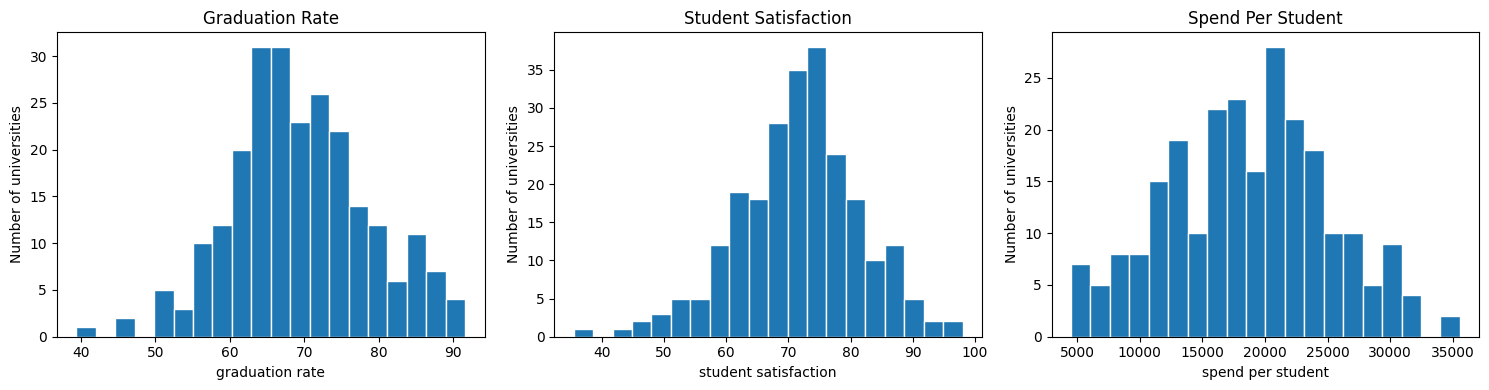

In [ ]:
if plt is None:
    print("Install matplotlib to show the histograms.")
else:
    columns_to_plot = ["graduation_rate", "student_satisfaction", "spend_per_student"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, column in zip(axes, columns_to_plot):
        ax.hist(universities[column], bins=20, edgecolor="white")
        ax.set_title(column.replace("_", " ").title())
        ax.set_xlabel(column.replace("_", " "))
        ax.set_ylabel("Number of universities")

    plt.tight_layout()
    plt.show()



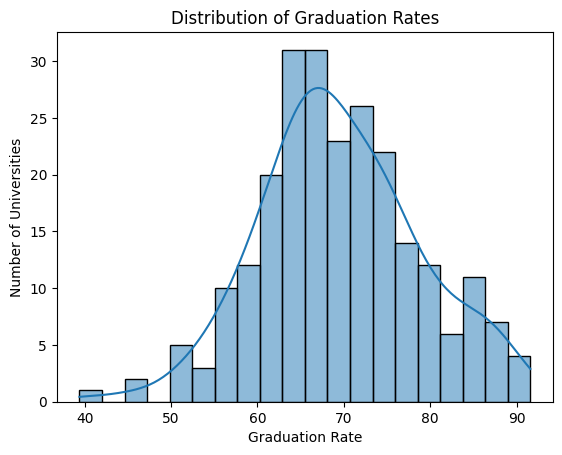

In [ ]:
# Plot histograms for the graduation rate using seaborn
import seaborn as sns
sns.histplot(data=universities, x="graduation_rate", bins=20, kde=True)
plt.xlabel("Graduation Rate")
plt.ylabel("Number of Universities")
plt.title("Distribution of Graduation Rates")
plt.show()


## 11. Hypothesis testing: set up H0 and H1

Question:

> Do private and non-private universities have different average graduation rates?

Hypotheses:

$$ \text{Denote } \mu_{private} \text{ as the mean graduation rate of private universities} $$

$$ \text{Denote } \mu_{not\ private} \text{ as the mean graduation rate of non-private universities} $$

Mathematically, we can write our hypothesis as

$$H_0: \mu_{private} - \mu_{not\ private} = 0$$

$$H_1: \mu_{private} - \mu_{not\ private} 
\neq 0$$





In [16]:
# Apply filter to filter out private universities and non-private universities

private_grad = universities.loc[universities["private"] == "Yes", "graduation_rate"]
not_private_grad = universities.loc[universities["private"] == "No", "graduation_rate"]

observed_difference = private_grad.mean() - not_private_grad.mean()


In [17]:
# Present the average graduation rate
print("Mean graduation rate, private:", round(private_grad.mean(), 2))
print("Mean graduation rate, not private:", round(not_private_grad.mean(), 2))
print("Observed difference:", round(observed_difference, 2))



Mean graduation rate, private: 72.42
Mean graduation rate, not private: 67.37
Observed difference: 5.05


#### Discussion

* Do we have enough evidence to suggest the mean graduation rate is different? 
* Where does it land in the context of building our machine learning model?


---


[Your comments here]



---

## 12. Welch's t-test in Python

Welch's t-test is a standard statistical test for comparing two group means.

Use it when you want to test whether two groups have different average values, without assuming equal variance.





In [ ]:
t_statistic, t_p_value = stats.ttest_ind(
        private_grad,
        not_private_grad,
        equal_var=False,
    )
print("Welch's t-test")
print("t-statistic:", round(t_statistic, 3))

#print the p-value to 4 decimal places to determine if the difference is statistically significant
# print the format to 4 decimal places using %.1f

print("p-value:", round(t_p_value, 6))





Welch's t-test
t-statistic: 4.338
p-value: 2.2e-05


#### How do we interpret the test result?

Discuss and mark down your comments

---


[Your comments here]



---

## 13. Chi-square test in Python

A chi-square test checks whether two categorical variables are associated.

Here we test:

* `private`
* `strong_outcome`

Null hypothesis:

$$H_0: 	\text{private status and strong outcome are independent}$$

In plain English, we want to know being a private university make a differnce in delivering a strong outcome, i.e. higher graduation rate



In [19]:
# First we create a contingency table using crosstab 
contingency_table = pd.crosstab(universities["private"], universities["strong_outcome"])




In [20]:
# In Chi-square test , we run the test 

chi2_statistic, chi2_p_value, degrees_of_freedom, expected_counts = stats.chi2_contingency(contingency_table)

print()
print("Chi-square test of independence")
print("chi-square statistic:", round(chi2_statistic, 3))
print("degrees of freedom:", degrees_of_freedom)
print("p-value:", round(chi2_p_value, 6))




Chi-square test of independence
chi-square statistic: 10.75
degrees of freedom: 1
p-value: 0.001043


### Discussion

* What is your interpretation of the test result?
* How do we associate the result to building our machine learning model?


## 14. Interpret hypothesis tests

When you explain a test, include:

1. the question
2. the null hypothesis
3. the p-value
4. the plain-English meaning
5. the caution: statistical evidence is not the same as causal proof





In [21]:
alpha = 0.05

if chi2_p_value < alpha:
    print("Chi-square test: reject H0 at the 5% level.")
    print("Plain English: private status is associated with the outcome.")
else:
    print("Chi-square test: do not reject H0 at the 5% level.")
    print("Plain English: private status is not associated with the outcome.")



Chi-square test: reject H0 at the 5% level.
Plain English: private status is associated with the outcome.


## 15. Correlation

Correlation measures how two numeric variables move together.

**Demo prompt:** Which feature has the strongest relationship with graduation rate?





In [ ]:
correlation_columns = [
    "graduation_rate",
    "spend_per_student",
    "student_satisfaction",
    "research_score",
    "staff_student_ratio",
    "acceptance_rate",
    "enrolment_rate",
]

correlations = universities[correlation_columns].corr()["graduation_rate"].sort_values(ascending=False).round(3)
correlations


corr_matrix = universities[correlation_columns].corr(numeric_only=).round(3)


graduation_rate         1.000
spend_per_student       0.452
research_score          0.254
student_satisfaction    0.223
acceptance_rate        -0.034
enrolment_rate         -0.039
staff_student_ratio    -0.261
Name: graduation_rate, dtype: float64

## 16. Correlation is not causation

Spend per student is correlated with graduation rate.

That does not prove that increasing spend causes higher graduation rates. Other factors may explain both.

**Discussion prompt:** What extra data would help us make a stronger causal claim?





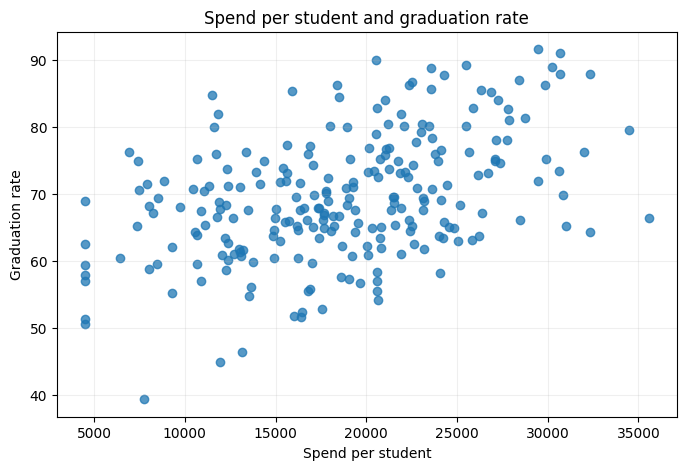

In [23]:
# Create the chart to display relationship

plt.figure(figsize=(8, 5))
plt.scatter(universities["spend_per_student"], universities["graduation_rate"], alpha=0.75)
plt.xlabel("Spend per student")
plt.ylabel("Graduation rate")
plt.title("Spend per student and graduation rate")
plt.grid(alpha=0.2)
plt.show()



## 17. Simpson's paradox check

Simpson's paradox happens when an overall pattern reverses after grouping.

This dataset does not show a perfect reversal in this comparison, but it does show why subgroup checks matter.





In [24]:
aggregate_acceptance = (
    universities
    .groupby("region")
    .agg(
        universities=("university_id", "count"),
        spend_per_student=("spend_per_student", "mean"),
        average_graduation_rate=("graduation_rate", "mean"),
    )
    .round(3)
)

aggregate_acceptance



,universities,spend_per_student,average_graduation_rate
region,,,
East,56,17660.856,70.423
North,67,19270.648,70.718
South,57,19805.388,69.400
West,60,17741.798,67.442


## 18. Grouped comparison

Now split the acceptance-rate comparison by region.

**Interpretation prompt:** Does the subgroup view tell the same story as the aggregate view?





In [25]:
by_region_acceptance = (
    universities
    .groupby(["region", "funding_band"])
    .agg(
        universities=("university_id", "count"),
        spend_per_student=("strong_outcome", "mean"),
        average_graduation_rate=("graduation_rate", "mean"),
    )
    .round(3)
)

by_region_acceptance



universities  spend_per_student  average_graduation_rate
region funding_band                                                          
East   High                    15              0.400                   70.167
       Low                     16              0.312                   69.644
       Medium                  25              0.480                   71.076
North  High                    13              0.692                   76.477
       Low                     24              0.542                   72.546
       Medium                  30              0.233                   66.760
South  High                    19              0.474                   73.447
       Low                     15              0.267                   67.487
       Medium                  23              0.348                   67.304
West   High                    14              0.214                   67.250
       Low                     16              0.125                   65.644
       Medium                  30              0.333                   68.490

### 19. Final activity

Write a short recommendation for a university support director.

Include:

1. one statistical measure
2. one probability or conditional probability
3. one hypothesis test result
4. one correlation-versus-causation warning
5. one subgroup or Simpson's paradox warning





In [26]:
# Write your recommendation in a markdown cell below.



### 20. Save our dataset for our next section

* Save the processed dataset for our next section 

In [27]:
universities.to_csv("universities_cleaned.csv", index=False)

## Key takeaways

* Mathematical notation is a compact way to describe statistical ideas.
* Probability can be estimated from data by counting rows.
* Statistical measures describe centre and spread.
* Hypothesis tests compare the observed result with what might happen under a null assumption.
* Welch's t-test and the chi-square test are common Python tools for hypothesis testing.
* Correlation is not causation.
* Simpson's paradox is a reason to check subgroups before trusting aggregate results.




---

### Final caveat

#### 1. **Averages Hide Complexity**
The mean alone is insufficient. You must understand the higher moments (mean, variance, skewness, kurtosis) to get a complete picture of your data's shape and behaviour.

**Real-world example:** A policy with mean outcome = 10 minutes is NOT the same whether all observations are between 8-12 minutes or some are 2 minutes and others are 95 minutes.

#### 2. **Visual Inspection is Your First Defence**
Before running any complex models:
- Plot a histogram + overlay the normal curve
- Create a Q-Q plot
- Look at the data with fresh eyes

Visual methods often reveal problems that formal tests miss and are interpretable to non-technical stakeholders.

#### 3. **Normality Testing Guides Model Selection**
- **If data is normal:** Parametric methods (linear regression, t-tests) are appropriate and efficient
- **If data is non-normal:** Consider transformations, non-parametric alternatives, or robust methods
- **Large samples:** Central Limit Theorem provides some protection against non-normality

#### 4. **Non-Normality ≠ Model Failure**
Non-normal data doesn't mean your model will fail, especially with:
- Large sample sizes (n > 500)
- Robust algorithms (tree-based models)
- Proper diagnostics and residual checking

However, it DOES mean you must be more careful and validate assumptions.

#### 5. **Context Matters More Than Rules**
The 'best' approach depends on:
- Your sample size
- Your model type
- The stakes of your decision (Is this resource allocation? Clinical diagnosis? Budget forecasting?)
- Your audience's technical understanding

---

### Practical Workflow for any data science project

```
1. Load your data
   ↓
2. Compute the four moments (mean, var, skewness, kurtosis)
   ↓
3. Create a histogram + overlay normal curve → Do they match?
   ↓
4. Create a Q-Q plot → Do points fall on the diagonal?
   ↓
5. Decision point:
   ├─ If YES to both → Data is likely normal, proceed with parametric methods
   └─ If NO to either →
       ├─ Consider transformation (log, Box-Cox)
       ├─ Or use non-parametric methods
       └─ Or document the violation and proceed with caution
   ↓
6. Check your model's residuals using the same visual methods
```

---

### Decision Tree: What Should You Do?

```
Is your data normally distributed? (Visual check)
│
├─ YES → Use parametric methods (regression, t-test, ANOVA)
│         BUT: Still check residuals after modelling!
│
└─ NO → Three options:
         1. Transform the data (log, Box-Cox)
            Then test normality again
         
         2. Use non-parametric methods
            (Mann-Whitney U, Spearman correlation, tree models)
         
         3. Proceed with parametric methods
            BUT document the assumption violation
            AND use robust standard errors
```

---

### Common Mistakes to Avoid

❌ **Mistake 1:** Using only the mean to describe your data
✓ **Better:** Always report mean ± standard deviation AND median ± IQR

❌ **Mistake 2:** Assuming normality without checking
✓ **Better:** Always visualise first (histogram, Q-Q plot)

❌ **Mistake 3:** Automatically applying transformations
✓ **Better:** Check if transformation actually helps your downstream model

❌ **Mistake 4:** Reporting transformed model coefficients without backtransforming
✓ **Better:** If you log-transformed for modelling, exponentiate predictions for interpretation

❌ **Mistake 5:** Ignoring outliers because "the test says they're expected"
✓ **Better:** Investigate outliers (data quality issues? real phenomenon?)

---
